# Subjectivity Mining, Assignment 4, Group 9
Offensive language detection, in-domain and cross-domain

Group members: Ines Casado Vela, Martin Ranea Marina, Pablos Tselioudis Garmendia, Helian X. Liu

Content warning: this notebook shows offensive tweets from the datasets.

| Setting | Training data | Test data |
|---|---|---|
| In-domain | olid-train-small.csv | olid-test.csv |
| Cross-domain | hasoc-train.csv | olid-test.csv |

Labels: 0 = non-offensive, 1 = offensive. The same OLID test set is used in every experiment.

| Part | Content | Done by | Folder |
|---|---|---|---|
| 1 | Data analysis, evaluation function, Logistic Regression | Ines Casado Vela | block1_logreg |
| 2 | BERT | Helian X. Liu | block2_bert |
| 3 | HateBERT | Martin Ranea Marina | block3_hatebert |
| 4 | fBERT and seed check | Pablos Tselioudis Garmendia | block4_fbert |
| 5 | Comparison of all models | Pablos Tselioudis Garmendia | figures, tables |

Notes on running the notebook:
- Parts 1 to 3 show the outputs from when each group member ran their part. BERT was trained in Google Colab and HateBERT on a local GPU.
- Each part first moves into its own folder, so it can be run again with its own files. Training the transformers needs a GPU and the simpletransformers library.
- Parts 4 and 5 load the saved fBERT predictions. Set RUN_TRAINING = True to train fBERT again.
- The report is in report/A4-report-Group9.pdf.

# Part 1. Data, evaluation function and Logistic Regression (Ines Casado Vela)

In [ ]:
import os
from pathlib import Path
FINAL_DIR = Path.cwd()
os.chdir(FINAL_DIR / 'block1_logreg')  # Block 1 files live here

## 1.1 Imports and random seed

The labels and the OLID test set are not changed anywhere in the notebook.

In [8]:
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)

## 1.2 Load the datasets

In [9]:
# Put the three CSV files in the same folder as this notebook.
DATA_DIR = Path(".")

OLID_TRAIN_PATH = DATA_DIR / "olid-train-small.csv"
OLID_TEST_PATH = DATA_DIR / "olid-test.csv"
HASOC_TRAIN_PATH = DATA_DIR / "hasoc-train.csv"

olid_train = pd.read_csv(OLID_TRAIN_PATH)
olid_test = pd.read_csv(OLID_TEST_PATH)
hasoc_train = pd.read_csv(HASOC_TRAIN_PATH)

datasets = {
    "OLID train small": olid_train,
    "HASOC train": hasoc_train,
    "OLID test": olid_test,
}

for name, df in datasets.items():
    print(name, df.shape)
    display(df.head(3))

OLID train small (5852, 3)


,id,text,labels
0,24590,@USER @USER @USER @USER @USER Hahah a left telling a right he is making everything political.. too f’n funny!,0
1,19287,@USER @USER I’m glad you do babe (I kiss you back) now let’s get going you are coming tomorrow to the final right babe,0
2,44676,@USER And I have concerns with”Democrats”,0


HASOC train (5852, 3)


,id,text,labels
0,hasoc_en_1,"#DhoniKeepsTheGlove | WATCH: Sports Minister Kiren Rijiju issues statement backing MS Dhoni over 'Balidaan Badge', t...",0
1,hasoc_en_2,@politico No. We should remember very clearly that #Individual1 just admitted to treason . #TrumpIsATraitor #McCain...,1
2,hasoc_en_3,@cricketworldcup Guess who would be the winner of this #CWC19? Team who gets maximum points from the abandoned m...,0


OLID test (860, 3)


,id,text,labels
0,15923,"#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA Democrats Support Antifa, Muslim Brotherhood, MS13, ISIS, Pedophilia,...",1
1,27014,"#ConstitutionDay is revered by Conservatives, hated by Progressives/Socialist/Democrats that want to change it.",0
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendment #RNC #USMC #veterans @USER @USER @USER @USER @USER #fakereporti...,0


### Checking the data

In [10]:
required_columns = {"id", "text", "labels"}

for name, df in datasets.items():
    assert required_columns.issubset(df.columns), f"{name}: missing columns"
    assert df["labels"].isin([0, 1]).all(), f"{name}: labels must be 0/1"
    assert df["text"].notna().all(), f"{name}: missing text values"

assert len(olid_train) == len(hasoc_train), (
    "The provided OLID-small and HASOC training sets are expected to have the same size."
)

print("Dataset checks passed.")

Dataset checks passed.


## 1.3 Dataset analysis

Size, class distribution and message length of each dataset. These numbers are used in the Data section of the report and later to discuss the cross-domain results.

In [11]:
def dataset_statistics(df):
    text = df["text"].astype(str)
    word_lengths = text.str.split().str.len()
    char_lengths = text.str.len()

    return {
        "instances": len(df),
        "class_0": int((df["labels"] == 0).sum()),
        "class_1": int((df["labels"] == 1).sum()),
        "offensive_%": round(100 * (df["labels"] == 1).mean(), 2),
        "mean_words": round(word_lengths.mean(), 2),
        "median_words": round(word_lengths.median(), 2),
        "mean_chars": round(char_lengths.mean(), 2),
        "median_chars": round(char_lengths.median(), 2),
    }

stats_df = pd.DataFrame(
    {name: dataset_statistics(df) for name, df in datasets.items()}
).T

display(stats_df)

,instances,class_0,class_1,offensive_%,mean_words,median_words,mean_chars,median_chars
OLID train small,5852.0,3591.0,2261.0,38.64,22.44,18.0,126.29,104.0
HASOC train,5852.0,3591.0,2261.0,38.64,23.29,21.0,167.04,158.0
OLID test,860.0,620.0,240.0,27.91,24.37,22.0,146.11,134.5


### Class distribution

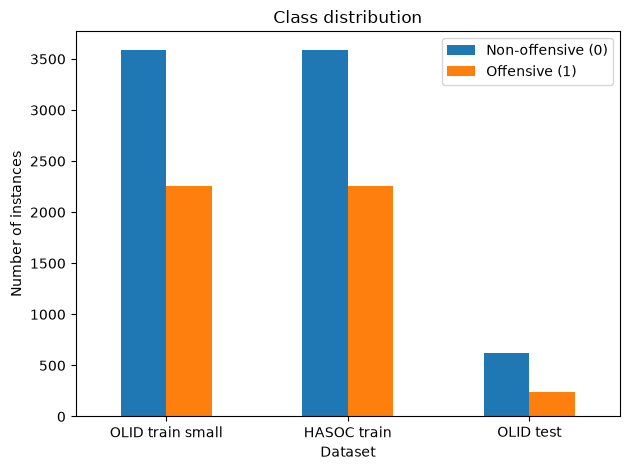

,Non-offensive (0),Offensive (1)
OLID train small,3591,2261
HASOC train,3591,2261
OLID test,620,240


In [12]:
class_counts = pd.DataFrame({
    name: df["labels"].value_counts().sort_index()
    for name, df in datasets.items()
}).T

class_counts.columns = ["Non-offensive (0)", "Offensive (1)"]

ax = class_counts.plot(kind="bar")
ax.set_title("Class distribution")
ax.set_xlabel("Dataset")
ax.set_ylabel("Number of instances")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(class_counts)

### Message length comparison

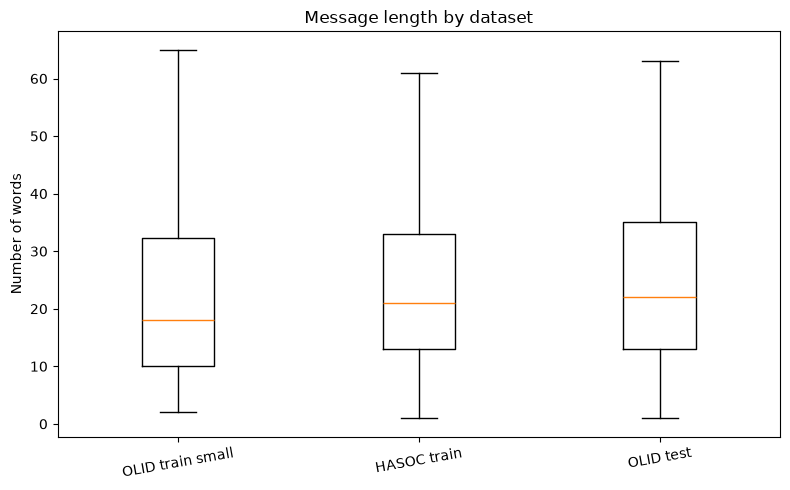

In [13]:
length_rows = []

for name, df in datasets.items():
    for length in df["text"].astype(str).str.split().str.len():
        length_rows.append({"dataset": name, "words": length})

length_df = pd.DataFrame(length_rows)

groups = [
    length_df.loc[length_df["dataset"] == name, "words"].values
    for name in datasets.keys()
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    groups,
    showfliers=False
)

plt.xticks(
    range(1, len(datasets) + 1),
    list(datasets.keys()),
    rotation=10
)

plt.title("Message length by dataset")
plt.ylabel("Number of words")
plt.tight_layout()
plt.show()

### Frequent content words

A simple count of the most frequent words, to see if OLID and HASOC are about different topics.

In [14]:
def top_terms(df, n=15):
    vectorizer = CountVectorizer(
        lowercase=True,
        stop_words="english",
        token_pattern=r"(?u)\b\w[\w#@]+\b",
    )
    matrix = vectorizer.fit_transform(df["text"].astype(str))
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    terms = vectorizer.get_feature_names_out()

    order = np.argsort(counts)[::-1][:n]
    return pd.DataFrame({
        "term": terms[order],
        "count": counts[order],
    })

print("OLID train small")
display(top_terms(olid_train))

print("HASOC train")
display(top_terms(hasoc_train))

OLID train small


,term,count
0,user,14230
1,url,887
2,gun,629
3,liberals,626
4,control,559
5,like,515
6,antifa,509
7,just,463
8,maga,453
9,conservatives,434


HASOC train


,term,count
0,fucktrump,1147
1,trumpisatraitor,870
2,icc,839
3,realdonaldtrump,733
4,doctorsfightback,689
5,trump,676
6,shameonicc,596
7,dhonikeepstheglove,573
8,doctors,430
9,amp,424


## 1.4 Common evaluation function

All models are scored with this function, so the results can be compared directly. It returns accuracy, macro precision, recall and F1, the scores for each class and the confusion matrix.

In [15]:
def evaluate_predictions(y_true, y_pred, model_name, setting, show_matrix=True):
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )

    row = {
        "model": model_name,
        "setting": setting,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p_macro,
        "macro_recall": r_macro,
        "macro_f1": f_macro,
        "precision_0": precision[0],
        "recall_0": recall[0],
        "f1_0": f1[0],
        "support_0": support[0],
        "precision_1": precision[1],
        "recall_1": recall[1],
        "f1_1": f1[1],
        "support_1": support[1],
    }

    summary = pd.DataFrame([row])

    if show_matrix:
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Non-offensive (0)", "Offensive (1)"],
        )
        disp.plot(values_format="d")
        plt.title(f"{model_name} - {setting}")
        plt.tight_layout()
        plt.show()

    return summary

## 1.5 Logistic Regression baseline

TF-IDF features of single words and word pairs, with Logistic Regression and balanced class weights. The same settings are used in both experiments, and the TF-IDF vocabulary is built only from the training set of each experiment.

In [16]:
def build_logreg_pipeline():
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                min_df=2,
                max_features=50000,
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=SEED,
            ),
        ),
    ])

## 1.6 Logistic Regression, in-domain

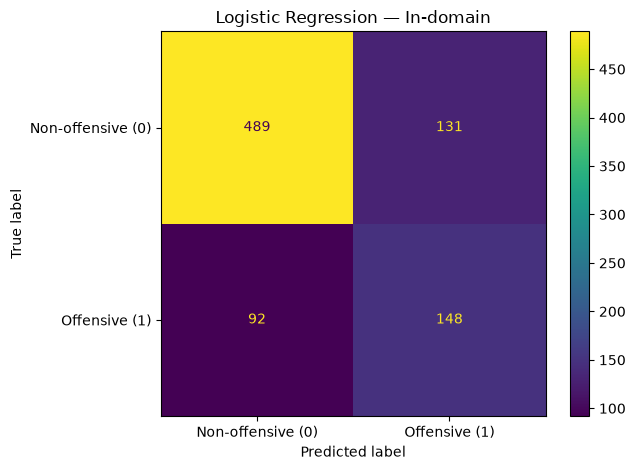

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Logistic Regression,In-domain,0.7407,0.6861,0.7027,0.6923,0.8417,0.7887,0.8143,620,0.5305,0.6167,0.5703,240


In [17]:
logreg_in = build_logreg_pipeline()

logreg_in.fit(olid_train["text"], olid_train["labels"])
pred_logreg_in = logreg_in.predict(olid_test["text"])

metrics_logreg_in = evaluate_predictions(
    olid_test["labels"],
    pred_logreg_in,
    model_name="Logistic Regression",
    setting="In-domain",
)

display(metrics_logreg_in.round(4))

results_logreg_in = olid_test.copy()
results_logreg_in["prediction"] = pred_logreg_in
results_logreg_in["correct"] = (
    results_logreg_in["labels"] == results_logreg_in["prediction"]
)

results_logreg_in.to_csv("results_logreg_in_domain.csv", index=False)
metrics_logreg_in.to_csv("metrics_logreg_in_domain.csv", index=False)

## 1.7 Logistic Regression, cross-domain

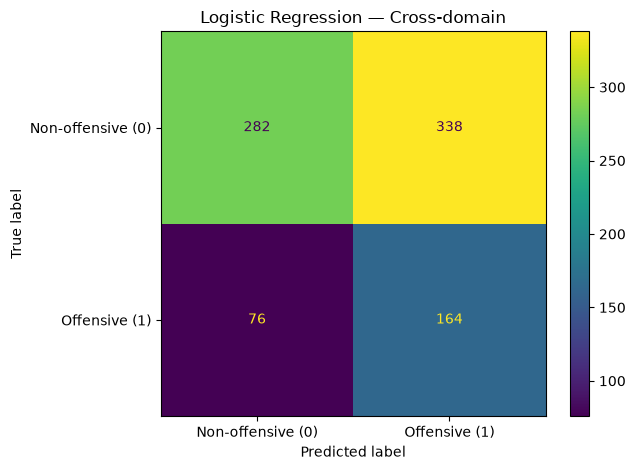

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Logistic Regression,Cross-domain,0.5186,0.5572,0.5691,0.5094,0.7877,0.4548,0.5767,620,0.3267,0.6833,0.442,240


In [18]:
logreg_cross = build_logreg_pipeline()

logreg_cross.fit(hasoc_train["text"], hasoc_train["labels"])
pred_logreg_cross = logreg_cross.predict(olid_test["text"])

metrics_logreg_cross = evaluate_predictions(
    olid_test["labels"],
    pred_logreg_cross,
    model_name="Logistic Regression",
    setting="Cross-domain",
)

display(metrics_logreg_cross.round(4))

results_logreg_cross = olid_test.copy()
results_logreg_cross["prediction"] = pred_logreg_cross
results_logreg_cross["correct"] = (
    results_logreg_cross["labels"] == results_logreg_cross["prediction"]
)

results_logreg_cross.to_csv("results_logreg_cross_domain.csv", index=False)
metrics_logreg_cross.to_csv("metrics_logreg_cross_domain.csv", index=False)

## 1.8 Logistic Regression, in-domain vs cross-domain

In [19]:
logreg_comparison = pd.concat(
    [metrics_logreg_in, metrics_logreg_cross],
    ignore_index=True,
)

display(logreg_comparison.round(4))

macro_f1_in = float(metrics_logreg_in.loc[0, "macro_f1"])
macro_f1_cross = float(metrics_logreg_cross.loc[0, "macro_f1"])

absolute_drop = macro_f1_in - macro_f1_cross
relative_drop = 100 * absolute_drop / macro_f1_in

print(f"In-domain macro-F1:   {macro_f1_in:.4f}")
print(f"Cross-domain macro-F1: {macro_f1_cross:.4f}")
print(f"Absolute macro-F1 drop: {absolute_drop:.4f}")
print(f"Relative macro-F1 drop: {relative_drop:.2f}%")

logreg_comparison.to_csv("metrics_logreg_comparison.csv", index=False)

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Logistic Regression,In-domain,0.7407,0.6861,0.7027,0.6923,0.8417,0.7887,0.8143,620,0.5305,0.6167,0.5703,240
1,Logistic Regression,Cross-domain,0.5186,0.5572,0.5691,0.5094,0.7877,0.4548,0.5767,620,0.3267,0.6833,0.4420,240


In-domain macro-F1:   0.6923
Cross-domain macro-F1: 0.5094
Absolute macro-F1 drop: 0.1830
Relative macro-F1 drop: 26.43%


## 1.9 Error examples

False positives and false negatives, used later in the error analysis.

In [20]:
def error_examples(results_df):
    false_positives = results_df[
        (results_df["labels"] == 0) & (results_df["prediction"] == 1)
    ]
    false_negatives = results_df[
        (results_df["labels"] == 1) & (results_df["prediction"] == 0)
    ]
    return false_positives, false_negatives

fp_in, fn_in = error_examples(results_logreg_in)
fp_cross, fn_cross = error_examples(results_logreg_cross)

print("IN-DOMAIN")
print("False positives:", len(fp_in))
print("False negatives:", len(fn_in))
display(fp_in.head(10))
display(fn_in.head(10))

print("\nCROSS-DOMAIN")
print("False positives:", len(fp_cross))
print("False negatives:", len(fn_cross))
display(fp_cross.head(10))
display(fn_cross.head(10))

IN-DOMAIN
False positives: 131
False negatives: 92


,id,text,labels,prediction,correct
1,27014,"#ConstitutionDay is revered by Conservatives, hated by Progressives/Socialist/Democrats that want to change it.",0,1,False
6,96874,#RAP is a form of ART! Used to express yourself freely. It does not gv the green light or excuse the behavior of act...,0,1,False
10,68123,#Conservatives - the party of low taxation 😂 #Tories #Tory URL,0,1,False
12,15565,#ConsTOO THE PLACE FOR FED UP CONSERVATIVES !!!,0,1,False
22,53563,"#kznlt Enjouji really is the prototype of my character brand, he is nothing but things that I love all rolled into o...",0,1,False
25,83155,#HIAC Damn Matt Hardy and Randy Orton put on one hell in a cell match!! Woooo!!! I hope he is okay!!,0,1,False
41,59200,"#Georgetown Classmate Says #Left Accuser is Absolutely NUTS"" URL ""Judge Kavanaugh""@USER @USER @USER #ABC #CBS #Demo...",0,1,False
42,30900,@USER @USER @USER Are you referring to how they lollygag with gun control as their kids get slaughtered in schools?,0,1,False
49,99680,Levi Strauss has “never been afraid to take an unpopular stand to support a greater good.” ' What about when they s...,0,1,False
52,50310,"0-9 : B-1, J-1, R-1, B-2, Q-2, B-3, BX-3, B-4, RB-4, Z-4, B-5, Q-5, B-6, H-6, B-7, H-7, UT-7, B-8 (20:59:36)",0,1,False


,id,text,labels,prediction,correct
4,60133,#NoPasaran: Unity demo to oppose the far-right in #London – #antifa #Oct13 — Enough is Enough! URL,1,0,False
7,65507,@USER Do you get the feeling he is kissing @USER behind so he can humiliate him later?,1,0,False
30,88490,#ChristineBlaseyFord is your #Kavanaugh accuser... #Liberals try this EVERY time... #ConfirmJudgeKavanaugh URL,1,0,False
43,44546,@USER @USER @USER @USER @USER @USER @USER @USER @USER I’m shocked to learn human traffickers had guns. Some probabl...,1,0,False
47,51628,#Conservatives @USER - You're a clown! URL,1,0,False
64,46139,#Conservatism101 It's not about our disagreements with #Conservatives. Its that Conservatives can't debate honestl...,1,0,False
77,98916,#ANTIFA are bedfellows with The Democratic Socialists of America (DSA) who #JamesOKeefe has exposed as being inserte...,1,0,False
80,32190,@USER Antifa has TS level influence. It's scary.,1,0,False
88,88905,#FortniteBattleRoyale #XboxShare @USER Please ban this cheating scum. he is literally invisible URL,1,0,False
99,37740,#SerenaWilliams is so full of herself...she is just as painful to watch as to listen to...,1,0,False



CROSS-DOMAIN
False positives: 338
False negatives: 76


,id,text,labels,prediction,correct
3,13876,#Watching #Boomer getting the news that she is still up for parole always makes me smile. #Wentworth Finale...@USER ...,0,1,False
6,96874,#RAP is a form of ART! Used to express yourself freely. It does not gv the green light or excuse the behavior of act...,0,1,False
9,46363,#BiggBossTamil janani won the task. She is going to first final list👏👏👏👏,0,1,False
10,68123,#Conservatives - the party of low taxation 😂 #Tories #Tory URL,0,1,False
11,22452,"𝓒-𝓒𝓮𝓭𝓻𝓪𝓷.. The Nord cannot make a single move, but he is fully aware of what is happening. A chill comes down his s...",0,1,False
12,15565,#ConsTOO THE PLACE FOR FED UP CONSERVATIVES !!!,0,1,False
13,64376,#GreatAwakening #QAnon #PatriotsUnited #WWG1WGA #AreYouAwake WHEN YOU ARE AWAKE YOU SEE CLEARLY ❤️🧡💛💚 Check out th...,0,1,False
16,65773,#Dayspromo week of September 17th #days #dool A coma does things to a gal . Sami: You are going to be ok. Hattie: N...,0,1,False
18,24930,#Dallas#Policewoman kills neighbor in HIS own apartment? WHAT went wrong?? See:Officer who shot man in his own apart...,0,1,False
21,70840,#Kavanaugh so a wild claim from 36 years ago of groping has evolved into A Rape A Violent Sexual Event by Move URL a...,0,1,False


,id,text,labels,prediction,correct
0,15923,"#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA Democrats Support Antifa, Muslim Brotherhood, MS13, ISIS, Pedophilia,...",1,0,False
4,60133,#NoPasaran: Unity demo to oppose the far-right in #London – #antifa #Oct13 — Enough is Enough! URL,1,0,False
14,12588,@USER Nigga ware da hits at,1,0,False
30,88490,#ChristineBlaseyFord is your #Kavanaugh accuser... #Liberals try this EVERY time... #ConfirmJudgeKavanaugh URL,1,0,False
59,15998,*gets all the bitches*,1,0,False
61,96457,#Antifa: Take note of how to protest with civility. This is why socialism (aka communism) will never win. It is in...,1,0,False
80,32190,@USER Antifa has TS level influence. It's scary.,1,0,False
107,47445,". JEFF SESSIONS: ‘LISTEN TO THE ACLU, ANTIFA, BLACK LIVES MATTER’ IF YOU WANT MORE CHICAGO SHOOTINGS . URL",1,0,False
115,42325,#Conservatives Govt ' @USER made my life hell': whistleblowers say they were threatened by regulator; I thought this...,1,0,False
130,58026,#MAGA #Qanon #GreatAwakening #inners #WWG1WGA #NowComesThePain #WalkAway #GoodbyeDemocrats Ellison Accuser Says Sh...,1,0,False


# Part 2. BERT (Helian X. Liu)

BERT was trained in Google Colab with a GPU, using Simple Transformers. The outputs below are the original Colab outputs. The evaluation function and the dataframes come from Part 1. Settings that are not in bert_args are the Simple Transformers defaults.

In [ ]:
os.chdir(FINAL_DIR / 'block2_bert')  # BERT outputs are saved here

In [11]:
!pip install -q simpletransformers

In [40]:
from simpletransformers.classification import ClassificationModel

In [ ]:
# Prepare data for BERT

bert_olid_train = olid_train[["text", "labels"]].copy()
bert_hasoc_train = hasoc_train[["text", "labels"]].copy()
bert_olid_test = olid_test[["text", "labels"]].copy()

# Data types
bert_olid_train["text"] = bert_olid_train["text"].astype(str)
bert_hasoc_train["text"] = bert_hasoc_train["text"].astype(str)
bert_olid_test["text"] = bert_olid_test["text"].astype(str)

bert_olid_train["labels"] = bert_olid_train["labels"].astype(int)
bert_hasoc_train["labels"] = bert_hasoc_train["labels"].astype(int)
bert_olid_test["labels"] = bert_olid_test["labels"].astype(int)

print("BERT OLID train:", bert_olid_train.shape)
print("BERT HASOC train:", bert_hasoc_train.shape)
print("BERT OLID test:", bert_olid_test.shape)

print("\nLabel distributions:")
print("OLID train:")
print(bert_olid_train["labels"].value_counts().sort_index())

print("\nHASOC train:")
print(bert_hasoc_train["labels"].value_counts().sort_index())

print("\nOLID test:")
print(bert_olid_test["labels"].value_counts().sort_index())

BERT OLID train: (5852, 2)
BERT HASOC train: (5852, 2)
BERT OLID test: (860, 2)

Label distributions:
OLID train:
labels
0    3591
1    2261
Name: count, dtype: int64

HASOC train:
labels
0    3591
1    2261
Name: count, dtype: int64

OLID test:
labels
0    620
1    240
Name: count, dtype: int64


In [44]:
# BERT configuration

BERT_CHECKPOINT = "bert-base-cased"

bert_args = {
    "num_train_epochs": 3,
    "train_batch_size": 16,
    "eval_batch_size": 16,
    "learning_rate": 4e-5,
    "max_seq_length": 128,

    "overwrite_output_dir": True,
    "reprocess_input_data": True,

    "save_steps": -1,
    "save_model_every_epoch": False,

    "use_multiprocessing": False,
    "use_multiprocessing_for_evaluation": False,

    "manual_seed": 42,

    "silent": False,
}

print("Checkpoint:", BERT_CHECKPOINT)
print("Training parameters:")
for key, value in bert_args.items():
    print(f"{key}: {value}")

Checkpoint: bert-base-cased
Training parameters:
num_train_epochs: 3
train_batch_size: 16
eval_batch_size: 16
learning_rate: 4e-05
max_seq_length: 128
overwrite_output_dir: True
reprocess_input_data: True
save_steps: -1
save_model_every_epoch: False
use_multiprocessing: False
use_multiprocessing_for_evaluation: False
manual_seed: 42
silent: False


In [ ]:
# BERT - in-domain model

bert_in_model = ClassificationModel(
    "bert",
    BERT_CHECKPOINT,
    num_labels=2,
    args={
        **bert_args,
        "output_dir": "outputs/bert_in_domain",
        "best_model_dir": "outputs/bert_in_domain/best_model",
    },
    use_cuda=True,
)

In [ ]:
# Train BERT on OLID (in-domain)

global_step, training_details = bert_in_model.train_model(
    bert_olid_train
)

In [ ]:
# BERT - in-domain prediction on OLID test

pred_bert_in, raw_outputs_bert_in = bert_in_model.predict(
    bert_olid_test["text"].tolist()
)

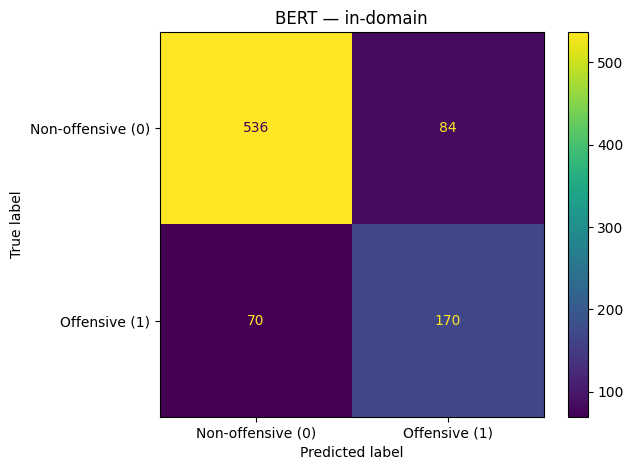

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,BERT,in-domain,0.82093,0.77689,0.786425,0.781324,0.884488,0.864516,0.874388,620,0.669291,0.708333,0.688259,240


In [50]:
# Evaluate BERT - in-domain

metrics_bert_in = evaluate_predictions(
    y_true=bert_olid_test["labels"].values,
    y_pred=pred_bert_in,
    model_name="BERT",
    setting="in-domain"
)

display(metrics_bert_in)

In [ ]:
# Save BERT - in-domain results

metrics_bert_in.to_csv(
    "metrics_bert_in_domain.csv",
    index=False
)

results_bert_in = olid_test.copy()
results_bert_in["prediction"] = pred_bert_in

results_bert_in.to_csv(
    "results_bert_in_domain.csv",
    index=False
)

In [ ]:
# BERT - cross-domain model

bert_cross_model = ClassificationModel(
    "bert",
    BERT_CHECKPOINT,
    num_labels=2,
    args={
        **bert_args,
        "output_dir": "outputs/bert_cross_domain",
        "best_model_dir": "outputs/bert_cross_domain/best_model",
    },
    use_cuda=True,
)

In [ ]:
# Train BERT on HASOC (cross-domain)

global_step_cross, training_details_cross = bert_cross_model.train_model(
    bert_hasoc_train
)

In [ ]:
# BERT - cross-domain prediction on OLID test

pred_bert_cross, raw_outputs_bert_cross = bert_cross_model.predict(
    bert_olid_test["text"].tolist()
)

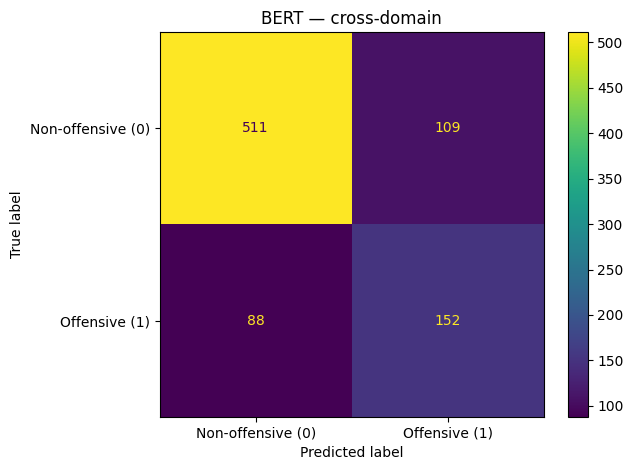

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,BERT,cross-domain,0.77093,0.717732,0.728763,0.722589,0.853088,0.824194,0.838392,620,0.582375,0.633333,0.606786,240


In [55]:
# Evaluate BERT - cross-domain

metrics_bert_cross = evaluate_predictions(
    y_true=bert_olid_test["labels"].values,
    y_pred=pred_bert_cross,
    model_name="BERT",
    setting="cross-domain"
)

display(metrics_bert_cross)

In [ ]:
# Save BERT - cross-domain results

metrics_bert_cross.to_csv(
    "metrics_bert_cross_domain.csv",
    index=False
)

results_bert_cross = olid_test.copy()
results_bert_cross["prediction"] = pred_bert_cross

results_bert_cross.to_csv(
    "results_bert_cross_domain.csv",
    index=False
)

In [57]:
# BERT - in-domain vs cross-domain comparison

metrics_bert_comparison = pd.concat(
    [metrics_bert_in, metrics_bert_cross],
    ignore_index=True
)

in_f1 = metrics_bert_in.loc[0, "macro_f1"]
cross_f1 = metrics_bert_cross.loc[0, "macro_f1"]

absolute_drop = in_f1 - cross_f1
relative_drop = absolute_drop / in_f1 * 100

display(metrics_bert_comparison)

print(f"In-domain macro-F1:    {in_f1:.4f}")
print(f"Cross-domain macro-F1: {cross_f1:.4f}")
print(f"Absolute F1 drop:       {absolute_drop:.4f}")
print(f"Relative F1 drop:       {relative_drop:.2f}%")

metrics_bert_comparison.to_csv(
    "metrics_bert_comparison.csv",
    index=False
)

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,BERT,in-domain,0.82093,0.776890,0.786425,0.781324,0.884488,0.864516,0.874388,620,0.669291,0.708333,0.688259,240
1,BERT,cross-domain,0.77093,0.717732,0.728763,0.722589,0.853088,0.824194,0.838392,620,0.582375,0.633333,0.606786,240


In-domain macro-F1:    0.7813
Cross-domain macro-F1: 0.7226
Absolute F1 drop:       0.0587
Relative F1 drop:       7.52%


## 2.1 BERT results

Model: bert-base-cased, 3 epochs, batch size 16, learning rate 4e-5, max length 128.

In-domain macro-F1 is 0.7813 and cross-domain macro-F1 is 0.7226, a drop of 0.0587 (7.52%). The drop is bigger for the offensive class, where F1 goes from 0.6883 to 0.6068.

# Part 3. HateBERT (Martin Ranea Marina)

HateBERT was trained with hatebert_block3.py on a local RTX 4060 laptop GPU. The cells below load the saved results and check them (RUN_TRAINING = False). The trained models are about 420 MB each and are not included.

In [ ]:
os.chdir(FINAL_DIR / 'block3_hatebert')  # Block 3 scripts, data and results live here

## 3.1 Setup

To train again, install the packages in block3_hatebert/requirements.txt and use a GPU. The exact settings and versions of each run are saved in hatebert_results/run_hatebert_*.json. Reading the saved results does not need a GPU.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from hatebert_block3 import CHECKPOINT, REVISION, TRAINING, load_data, run_setting, compare_results
from shared_evaluation import evaluate_predictions

DATA_DIR = Path('.')
RUN_TRAINING = False
RESULTS_DIR = Path('hatebert_results_rerun' if RUN_TRAINING else 'hatebert_results')
MODELS_DIR = Path('hatebert_models_rerun')
print('Checkpoint:', CHECKPOINT)
print('Pinned revision:', REVISION)
print('Mode:', 'fresh training' if RUN_TRAINING else 'inspect delivered results')


Checkpoint: GroNLP/hateBERT
Pinned revision: ab7a2d40f6c973cb57e63f23bfa2b51d981d028c
Mode: inspect delivered results


## 3.2 Data

In-domain: train on olid-train-small.csv, test on olid-test.csv. Cross-domain: train on hasoc-train.csv, test on the same olid-test.csv. Both training sets have 5,852 messages (3,591 non-offensive, 2,261 offensive), the test set has 860 (620 and 240). The text is not changed, apart from the normal lowercasing and tokenization of the model. Messages longer than 128 tokens are cut off.

In [2]:
data = load_data(DATA_DIR)
display(pd.DataFrame([
    {'dataset': name, 'n': len(df), 'class_0': (df.labels == 0).sum(), 'class_1': (df.labels == 1).sum()}
    for name, df in data.items()
]))


,dataset,n,class_0,class_1
0,olid-train-small.csv,5852,3591,2261
1,hasoc-train.csv,5852,3591,2261
2,olid-test.csv,860,620,240


## 3.3 Model and training settings

HateBERT (Caselli et al., 2021) is BERT-base-uncased trained further on Reddit posts from banned communities. A classification layer is added and the whole model is fine-tuned, separately for each training set. The settings were fixed before looking at test results, with no tuning or early stopping, and the model after the last epoch is used. Batch size 8 with 2 accumulation steps gives an effective batch size of 16.

In [3]:
display(pd.DataFrame([TRAINING]).T.rename(columns={0: 'value'}))


,value
num_train_epochs,3
learning_rate,0.00002
train_batch_size,8
gradient_accumulation_steps,2
eval_batch_size,32
max_seq_length,128
optimizer,AdamW
scheduler,linear_schedule_with_warmup
warmup_ratio,0.06
warmup_steps,0


## 3.4 In-domain training and predictions

Only the OLID training data is used for training. The test set is only used for the predictions afterwards.

Delivered run: completed | NVIDIA GeForce RTX 4060 Laptop GPU
Optimizer steps: 1098
Training seconds: 173.6


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.714,240


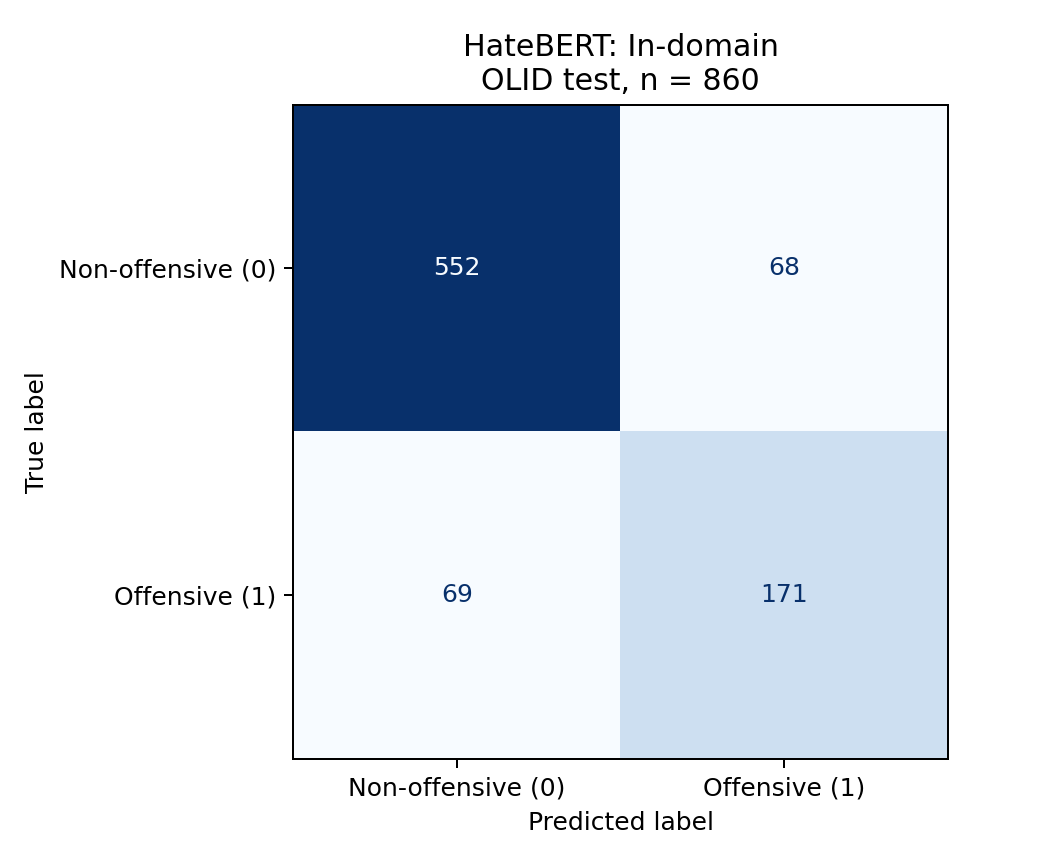

In [4]:
if RUN_TRAINING:
    run_setting('in_domain', DATA_DIR, RESULTS_DIR, MODELS_DIR)
else:
    run = json.loads((RESULTS_DIR / 'run_hatebert_in_domain.json').read_text(encoding='utf-8'))
    print('Delivered run:', run['status'], '|', run['gpu'])
    print('Optimizer steps:', run['global_optimizer_steps'])
    print('Training seconds:', round(run['training_seconds_including_initialization'], 1))

metrics_in = pd.read_csv(RESULTS_DIR / 'metrics_hatebert_in_domain.csv')
display(metrics_in.round(4))
display(Image(filename=str(RESULTS_DIR / 'confusion_hatebert_in_domain.png')))


## 3.5 Cross-domain training and predictions

A new model is loaded from the original HateBERT checkpoint and trained on HASOC, so nothing is reused from the in-domain model. The settings are the same as in 3.4.

Delivered run: completed | NVIDIA GeForce RTX 4060 Laptop GPU
Optimizer steps: 1098
Training seconds: 179.4


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,Cross-domain,0.8035,0.756,0.7513,0.7536,0.8596,0.8694,0.8645,620,0.6524,0.6333,0.6427,240


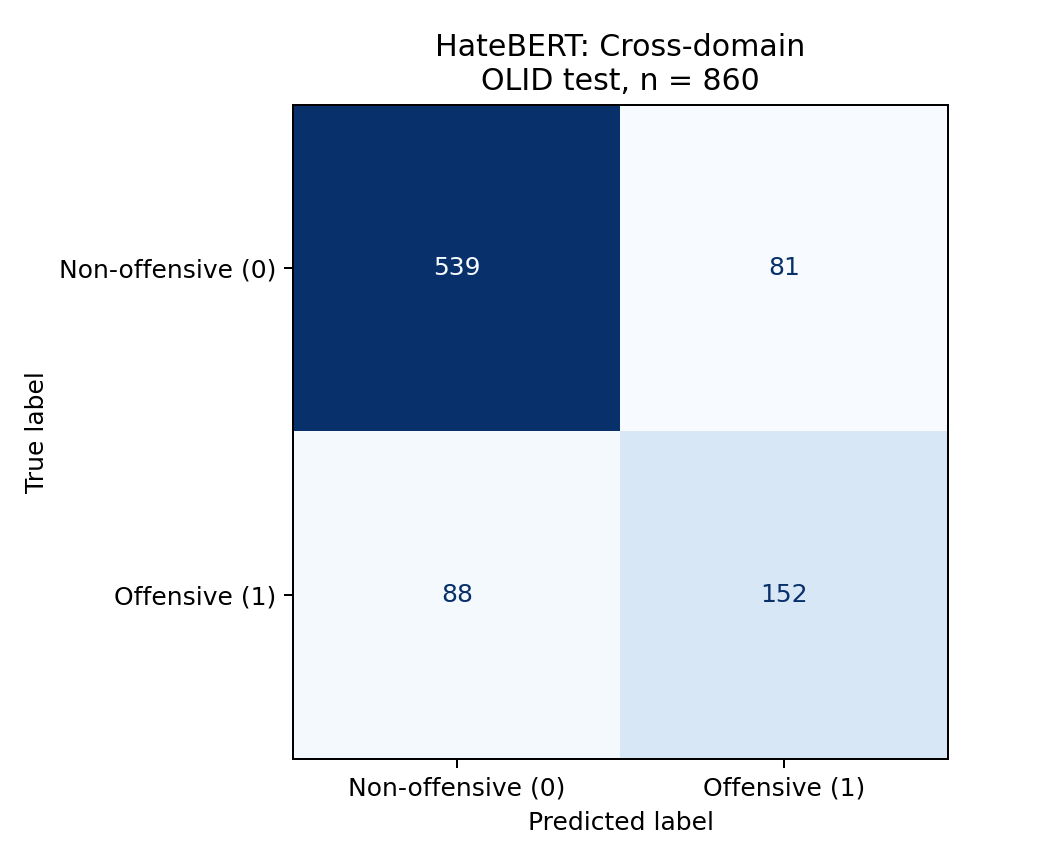

In [5]:
if RUN_TRAINING:
    run_setting('cross_domain', DATA_DIR, RESULTS_DIR, MODELS_DIR)
else:
    run = json.loads((RESULTS_DIR / 'run_hatebert_cross_domain.json').read_text(encoding='utf-8'))
    print('Delivered run:', run['status'], '|', run['gpu'])
    print('Optimizer steps:', run['global_optimizer_steps'])
    print('Training seconds:', round(run['training_seconds_including_initialization'], 1))

metrics_cross = pd.read_csv(RESULTS_DIR / 'metrics_hatebert_cross_domain.csv')
display(metrics_cross.round(4))
display(Image(filename=str(RESULTS_DIR / 'confusion_hatebert_cross_domain.png')))


## 3.6 Checking the scores with the shared evaluation function

shared_evaluation.py is a copy of the evaluation function from Part 1.

In [6]:
for setting in ['in_domain', 'cross_domain']:
    r = pd.read_csv(RESULTS_DIR / f'results_hatebert_{setting}.csv')
    assert r[['id','text','labels']].equals(data['olid-test.csv'][['id','text','labels']])
    expected = pd.read_csv(RESULTS_DIR / f'metrics_hatebert_{setting}.csv')
    actual = evaluate_predictions(r.labels, r.prediction, 'HateBERT', expected.setting.iloc[0], show_matrix=False)
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False, atol=1e-12, rtol=1e-12)
print('Both saved metric files exactly reproduce the common evaluation framework.')


Both saved metric files exactly reproduce the common evaluation framework.


## 3.7 In-domain vs cross-domain

The absolute drop is the in-domain macro-F1 minus the cross-domain macro-F1. The relative drop divides this by the in-domain macro-F1.

In [7]:
comparison = compare_results(RESULTS_DIR)
display(comparison.round(4))
f_in, f_cross = comparison.macro_f1
print(f'Absolute macro-F1 drop: {f_in-f_cross:.4f}')
print(f'Percentage-point drop: {100*(f_in-f_cross):.2f}')
print(f'Relative drop: {100*(f_in-f_cross)/f_in:.2f}%')


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.7140,240
1,HateBERT,Cross-domain,0.8035,0.7560,0.7513,0.7536,0.8596,0.8694,0.8645,620,0.6524,0.6333,0.6427,240


Absolute macro-F1 drop: 0.0482
Percentage-point drop: 4.82
Relative drop: 6.01%


## 3.8 Error analysis

False positives, false negatives and error rates by message length. The paired outcomes show which test tweets each model gets right.

In [8]:
from analyze_hatebert import analyze
analyze(DATA_DIR, RESULTS_DIR)
for filename in ['error_summary_hatebert.csv','errors_by_length_hatebert.csv',
                 'paired_outcomes_hatebert.csv','data_audit_hatebert.csv']:
    print(filename)
    display(pd.read_csv(RESULTS_DIR / filename).round(4))


Verified both prediction files, every metric, confusion matrices and source data hashes.
error_summary_hatebert.csv


,setting,TN,FP,FN,TP,false_positive_rate,false_negative_rate,predicted_offensive_percent
0,in_domain,552,68,69,171,0.1097,0.2875,27.7907
1,cross_domain,539,81,88,152,0.1306,0.3667,27.0930


errors_by_length_hatebert.csv


,setting,length_group,n,offensive_support,errors,error_rate,false_positives,false_negatives
0,in_domain,0-15 words,275,89,36,0.1309,15,21
1,in_domain,16-30 words,305,86,50,0.1639,21,29
2,in_domain,31+ words,280,65,51,0.1821,32,19
3,cross_domain,0-15 words,275,89,54,0.1964,26,28
4,cross_domain,16-30 words,305,86,56,0.1836,18,38
5,cross_domain,31+ words,280,65,59,0.2107,37,22


paired_outcomes_hatebert.csv


,outcome,n
0,both_correct,653
1,both_wrong,99
2,only_in_domain_correct,70
3,only_cross_domain_correct,38


data_audit_hatebert.csv


,dataset,instances,class_0,class_1,mean_words,mean_characters,mean_wordpieces_with_special_tokens,max_wordpieces_with_special_tokens,truncated_at_128,truncated_percent,duplicate_text_rows,exact_text_overlap_with_test,sha256
0,olid-train-small.csv,5852,3591,2261,22.4354,126.2900,33.7449,169,14,0.2392,8,4.0,d8b0097defcc1a31f611fe07af7ef81f5e730e424507eb...
1,hasoc-train.csv,5852,3591,2261,23.2920,167.0448,47.4111,386,11,0.1880,78,0.0,780744468ef09fbd1be66bb87a12bfe581690662b4555b...
2,olid-test.csv,860,620,240,24.3721,146.1116,40.3047,94,0,0.0000,11,NaN,45259b2be5bd7cabd0c30375dd736898faf82ec47a489f...


### Some example errors

The first three errors of each type, in the order of the test set.

In [9]:
for setting in ['in_domain', 'cross_domain']:
    errors = pd.read_csv(RESULTS_DIR / f'errors_hatebert_{setting}.csv')
    print(setting)
    display(errors.groupby('error_type', sort=False).head(3)[['id','text','labels','prediction','error_type']])


in_domain


,id,text,labels,prediction,error_type
0,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0,false_negative
1,65507,@USER Do you get the feeling he is kissing @US...,1,0,false_negative
2,45712,"#BREAKING: After a week-long trial, a Linn Cou...",0,1,false_positive
3,53563,#kznlt Enjouji really is the prototype of my c...,0,1,false_positive
4,83155,#HIAC Damn Matt Hardy and Randy Orton put on ...,0,1,false_positive
5,88490,#ChristineBlaseyFord is your #Kavanaugh accuse...,1,0,false_negative


cross_domain


,id,text,labels,prediction,error_type
0,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0,false_negative
1,83155,#HIAC Damn Matt Hardy and Randy Orton put on ...,0,1,false_positive
2,76669,@USER *coffee spit* Spartacus moment? He neve...,0,1,false_positive
3,30900,@USER @USER @USER Are you referring to how the...,0,1,false_positive
4,30899,*voice in my head while I transfer money to my...,1,0,false_negative
5,40110,#Kids Beating #Paraplegic #Trump #Boy! #Left ...,1,0,false_negative


# Part 4. fBERT (Pablos Tselioudis Garmendia)

fBERT (Sarkar et al., 2021) is bert-base-uncased trained further on more than 1.4 million offensive tweets from SOLID, a large extension of OLID. Like HateBERT, it is a language model, so a classification layer is added and the whole model is fine-tuned.

To compare fBERT fairly with HateBERT, the same code and settings as in Part 3 are used. fbert_block4.py is hatebert_block3.py with only the model name changed. Settings: 3 epochs, AdamW, learning rate 2e-5, weight decay 0.01, 6% warmup, batch size 8 with 2 accumulation steps, max length 128, FP16, seed 42, no class weights. The cross-domain model starts again from the original fBERT checkpoint.

In [2]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

os.chdir(FINAL_DIR / 'block4_fbert')
sys.path.insert(0, str(Path.cwd()))
from fbert_block4 import CHECKPOINT, REVISION, TRAINING, load_data, run_setting, compare_results
from shared_evaluation import evaluate_predictions  # identical copy of Ines' function (Part 1)

RUN_TRAINING = False  # True retrains both models (about 2.5 minutes each on an RTX 4070 laptop GPU)
RESULTS_DIR = Path('fbert_results_rerun' if RUN_TRAINING else 'fbert_results')
MODELS_DIR = Path('fbert_models_rerun')
print('Checkpoint:', CHECKPOINT, '| revision:', REVISION)
display(pd.DataFrame([TRAINING]).T.rename(columns={0: 'value'}))

Checkpoint: diptanu/fBERT | revision: c089daa35cb177238dd91ffe3010c2d8bbd069bf


,value
num_train_epochs,3
learning_rate,0.00002
train_batch_size,8
gradient_accumulation_steps,2
eval_batch_size,32
max_seq_length,128
optimizer,AdamW
scheduler,linear_schedule_with_warmup
warmup_ratio,0.06
warmup_steps,0


## 4.1 In-domain: train on OLID train small, test on OLID test

Run: completed | NVIDIA GeForce RTX 4070 Laptop GPU | steps: 1098 | seconds: 132.5


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,fBERT,In-domain,0.8407,0.8014,0.8052,0.8033,0.8927,0.8855,0.8891,620,0.7102,0.725,0.7175,240


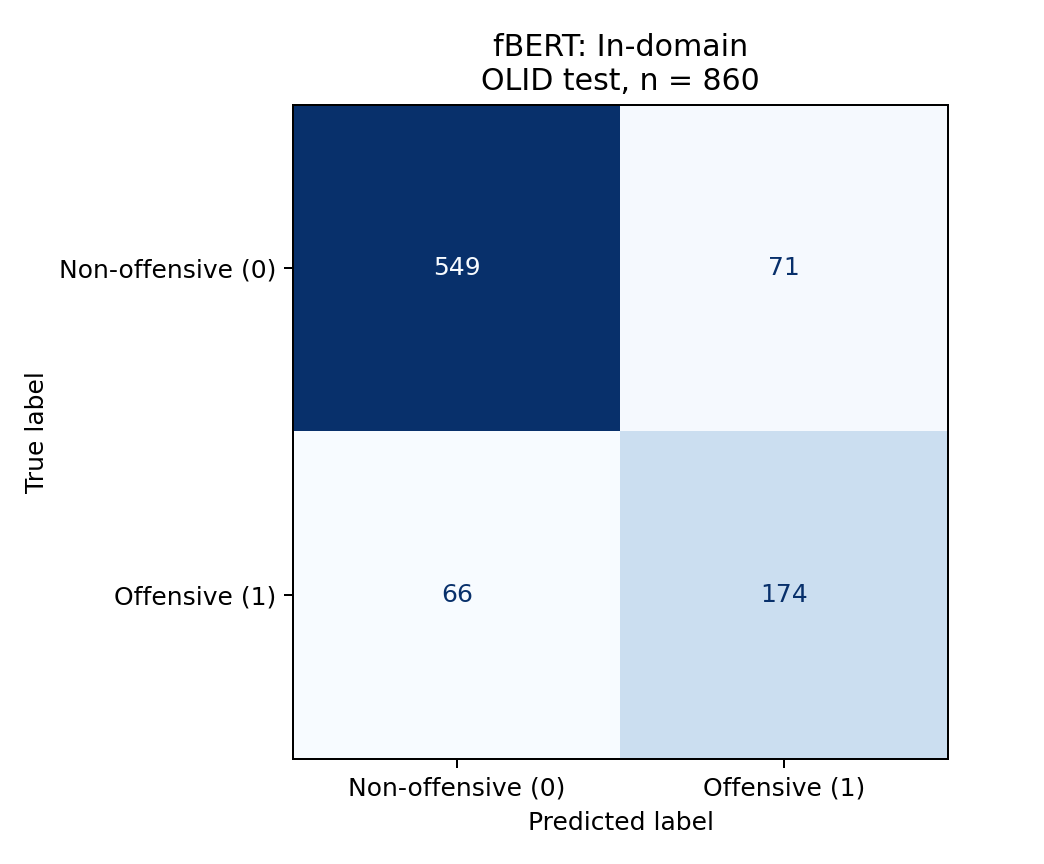

In [3]:
if RUN_TRAINING:
    run_setting('in_domain', '.', RESULTS_DIR, MODELS_DIR)
run = json.loads((RESULTS_DIR / 'run_fbert_in_domain.json').read_text())
print('Run:', run['status'], '|', run['gpu'], '| steps:', run['global_optimizer_steps'],
      '| seconds:', round(run['training_seconds_including_initialization'], 1))
display(pd.read_csv(RESULTS_DIR / 'metrics_fbert_in_domain.csv').round(4))
display(Image(filename=str(RESULTS_DIR / 'confusion_fbert_in_domain.png'), width=420))

## 4.2 Cross-domain: train on HASOC, test on OLID test

Run: completed | NVIDIA GeForce RTX 4070 Laptop GPU | steps: 1098 | seconds: 138.1


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,fBERT,Cross-domain,0.8547,0.8317,0.7932,0.8088,0.8744,0.9323,0.9024,620,0.7889,0.6542,0.7153,240


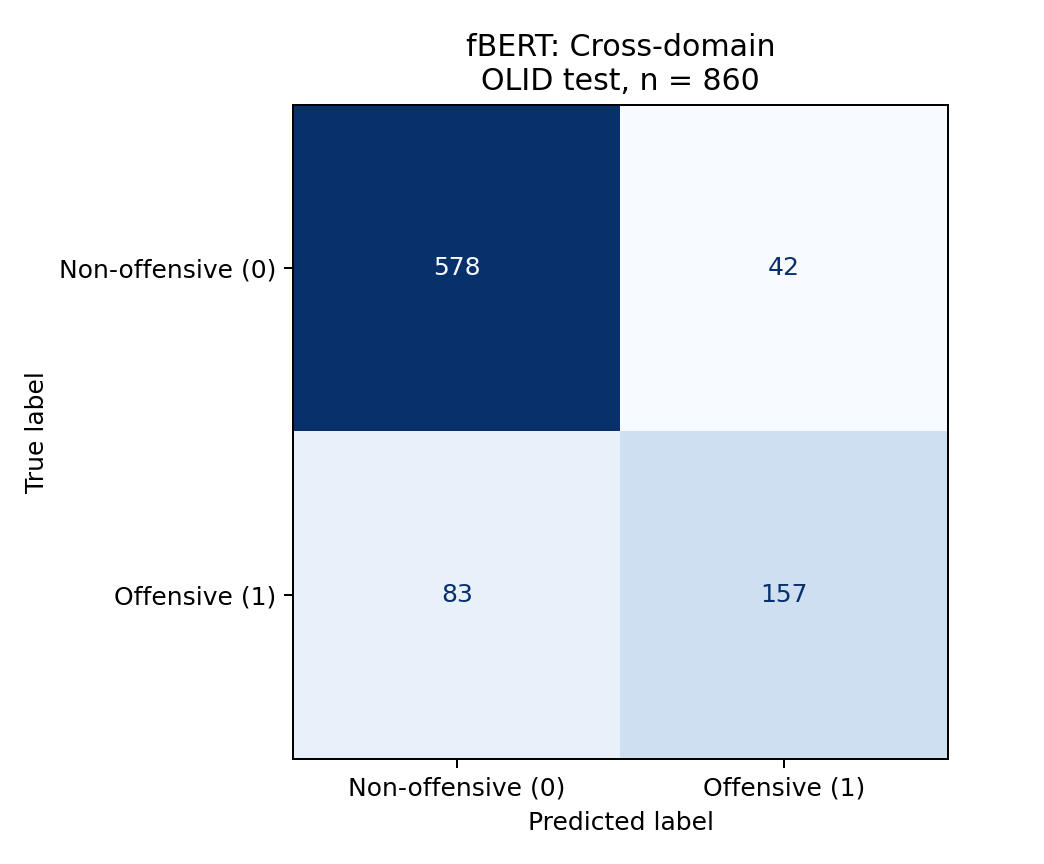

In [4]:
if RUN_TRAINING:
    run_setting('cross_domain', '.', RESULTS_DIR, MODELS_DIR)
run = json.loads((RESULTS_DIR / 'run_fbert_cross_domain.json').read_text())
print('Run:', run['status'], '|', run['gpu'], '| steps:', run['global_optimizer_steps'],
      '| seconds:', round(run['training_seconds_including_initialization'], 1))
display(pd.read_csv(RESULTS_DIR / 'metrics_fbert_cross_domain.csv').round(4))
display(Image(filename=str(RESULTS_DIR / 'confusion_fbert_cross_domain.png'), width=420))

## 4.3 Checking the scores with the shared evaluation function

In [5]:
test = load_data('.')['olid-test.csv']
for setting in ['in_domain', 'cross_domain']:
    r = pd.read_csv(RESULTS_DIR / f'results_fbert_{setting}.csv')
    assert r[['id', 'text', 'labels']].equals(test[['id', 'text', 'labels']]), 'test rows changed'
    saved = pd.read_csv(RESULTS_DIR / f'metrics_fbert_{setting}.csv')
    recomputed = evaluate_predictions(r.labels, r.prediction, 'fBERT', saved.setting.iloc[0], show_matrix=False)
    pd.testing.assert_frame_equal(recomputed, saved, check_dtype=False, atol=1e-12)
print('Saved fBERT metrics match the shared evaluation function for both settings.')

Saved fBERT metrics match the shared evaluation function for both settings.


## 4.4 In-domain vs cross-domain

In [6]:
fbert_comparison = compare_results(RESULTS_DIR)
display(fbert_comparison.round(4))
f_in, f_cross = fbert_comparison.macro_f1
print(f'In-domain macro-F1:    {f_in:.4f}')
print(f'Cross-domain macro-F1: {f_cross:.4f}')
print(f'Absolute drop:         {f_in - f_cross:.4f}')
print(f'Relative drop:         {100 * (f_in - f_cross) / f_in:.2f}%')

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,fBERT,In-domain,0.8407,0.8014,0.8052,0.8033,0.8927,0.8855,0.8891,620,0.7102,0.7250,0.7175,240
1,fBERT,Cross-domain,0.8547,0.8317,0.7932,0.8088,0.8744,0.9323,0.9024,620,0.7889,0.6542,0.7153,240


In-domain macro-F1:    0.8033
Cross-domain macro-F1: 0.8088
Absolute drop:         -0.0055
Relative drop:         -0.69%


fBERT does not drop in the cross-domain setting, the model trained on HASOC is even slightly better on the OLID test set. A likely reason is the data fBERT was pre-trained on. SOLID uses the OLID labelling scheme and its labels come from models trained on OLID, so fBERT already knows what offensive means in OLID before fine-tuning.

## 4.5 Seed check
The result of one training run can depend on the random seed. To check this, fBERT and HateBERT were trained again with seeds 1 and 2 (seed_check/run_seeds.py, same settings, models deleted afterwards). The main results are still the seed 42 runs.

In [7]:
seeds = []
for tag, model, main in [('hatebert', 'HateBERT', FINAL_DIR / 'block3_hatebert/hatebert_results'),
                         ('fbert', 'fBERT', RESULTS_DIR)]:
    for seed, folder in [(42, main), (1, Path(f'seed_check/{tag}_seed1')), (2, Path(f'seed_check/{tag}_seed2'))]:
        m = pd.read_csv(folder / f'metrics_{tag}_comparison.csv').set_index('setting')['macro_f1']
        seeds.append({'model': model, 'seed': seed, 'macro_f1_in': m['In-domain'], 'macro_f1_cross': m['Cross-domain']})
seeds = pd.DataFrame(seeds)
seeds['drop'] = seeds.macro_f1_in - seeds.macro_f1_cross
display(seeds.round(4))
display(seeds.groupby('model')[['macro_f1_in', 'macro_f1_cross', 'drop']].agg(['mean', 'std']).round(4))

,model,seed,macro_f1_in,macro_f1_cross,drop
0,HateBERT,42,0.8018,0.7536,0.0482
1,HateBERT,1,0.8037,0.7404,0.0633
2,HateBERT,2,0.7938,0.7163,0.0774
3,fBERT,42,0.8033,0.8088,-0.0055
4,fBERT,1,0.8050,0.8109,-0.0059
5,fBERT,2,0.8055,0.8041,0.0014


macro_f1_in         macro_f1_cross            drop        
                mean     std           mean     std    mean     std
model                                                              
HateBERT      0.7997  0.0053         0.7368  0.0189  0.0630  0.0146
fBERT         0.8046  0.0011         0.8079  0.0035 -0.0033  0.0041

# Part 5. Comparison of all models (Pablos Tselioudis Garmendia)

integrate_all.py loads the saved predictions of all four parts, checks that they are for the same 860 test tweets, scores them again with the shared evaluation function and compares this with each part's own score files. It saves the combined tables in tables/ and the figures in figures/. It also fixes the setting names, since Part 2 used lower case.

In [8]:
os.chdir(FINAL_DIR)
sys.path.insert(0, str(FINAL_DIR / 'block4_fbert'))
import integrate_all as ia

data = ia.load_data()
test = data['OLID test']
preds = ia.load_predictions(test)
final_results = ia.metrics_table(test, preds)  # also writes A4_all_model_metrics.csv
drops = ia.drop_table(final_results)
ia.error_tables(test, preds)
profile = ia.domain_profile(data)
ia.fig_macro_f1(final_results); ia.fig_class_f1(final_results); ia.fig_confusions(test, preds)
display(final_results.round(4))

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Logistic Regression,In-domain,0.7407,0.6861,0.7027,0.6923,0.8417,0.7887,0.8143,620,0.5305,0.6167,0.5703,240
1,Logistic Regression,Cross-domain,0.5186,0.5572,0.5691,0.5094,0.7877,0.4548,0.5767,620,0.3267,0.6833,0.4420,240
2,BERT,In-domain,0.8209,0.7769,0.7864,0.7813,0.8845,0.8645,0.8744,620,0.6693,0.7083,0.6883,240
3,BERT,Cross-domain,0.7709,0.7177,0.7288,0.7226,0.8531,0.8242,0.8384,620,0.5824,0.6333,0.6068,240
4,HateBERT,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.7140,240
5,HateBERT,Cross-domain,0.8035,0.7560,0.7513,0.7536,0.8596,0.8694,0.8645,620,0.6524,0.6333,0.6427,240
6,fBERT,In-domain,0.8407,0.8014,0.8052,0.8033,0.8927,0.8855,0.8891,620,0.7102,0.7250,0.7175,240
7,fBERT,Cross-domain,0.8547,0.8317,0.7932,0.8088,0.8744,0.9323,0.9024,620,0.7889,0.6542,0.7153,240


## 5.1 Macro-F1 and F1 per class

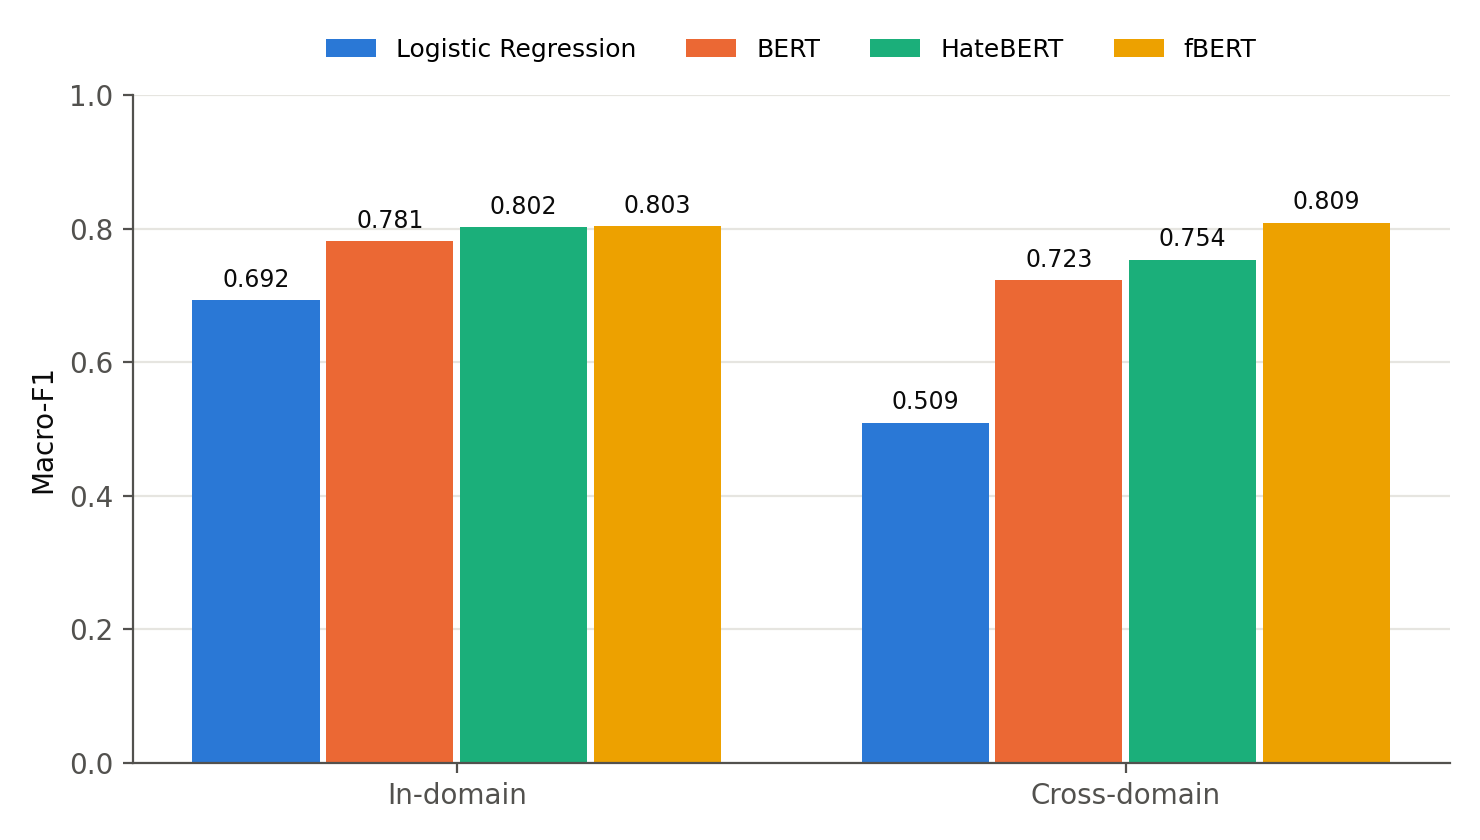

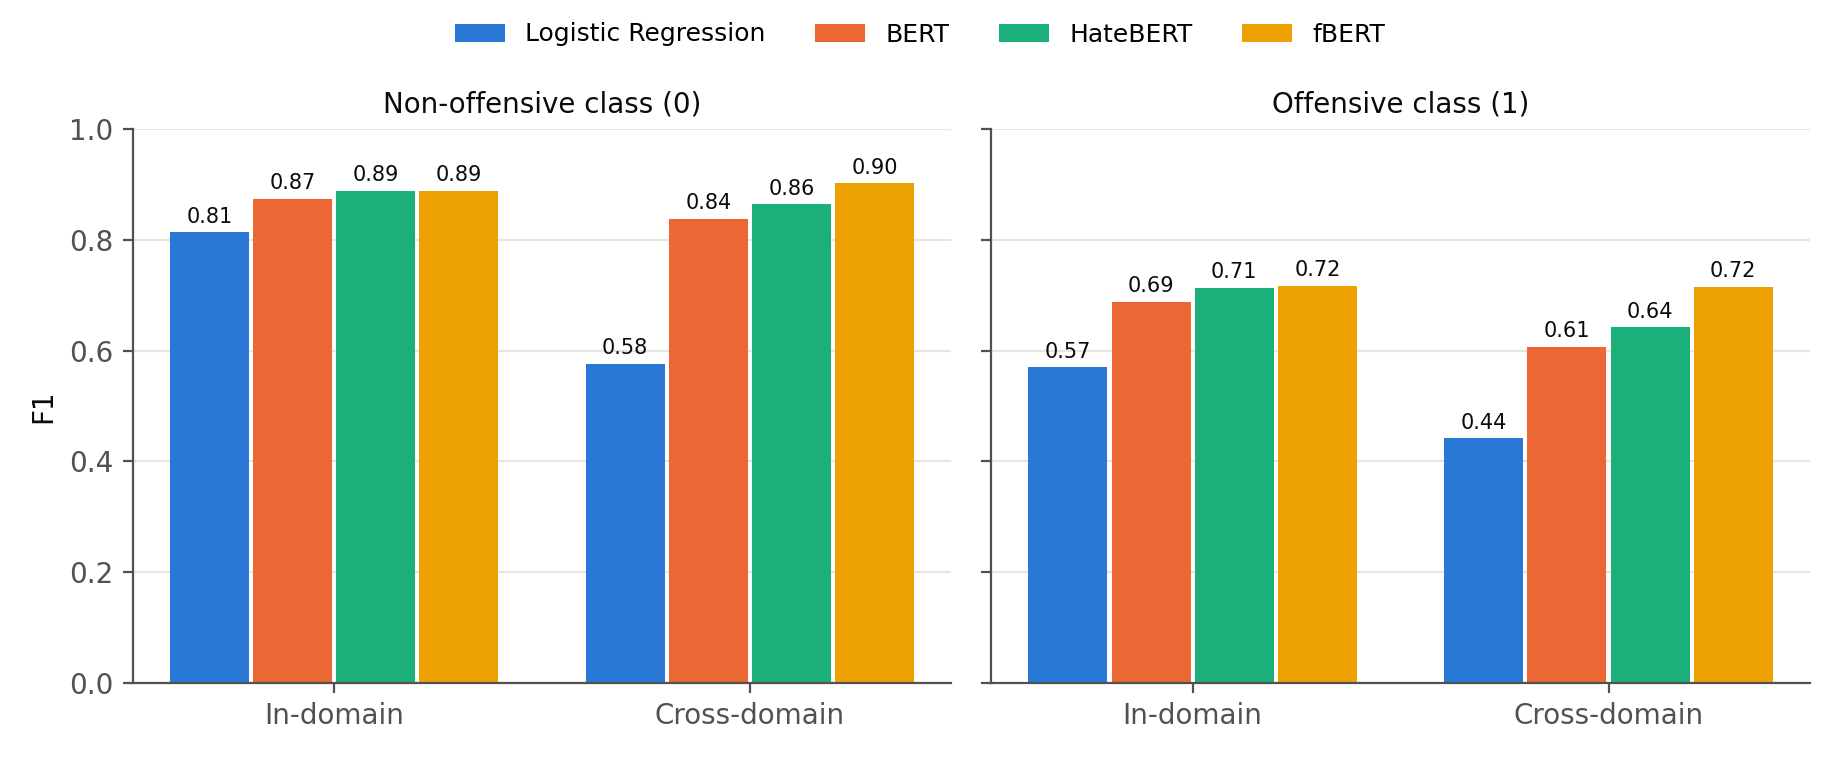

In [9]:
display(Image(filename='figures/macro_f1_all_models.png', width=700))
display(Image(filename='figures/class_f1_all_models.png', width=850))

## 5.2 Confusion matrices and error rates

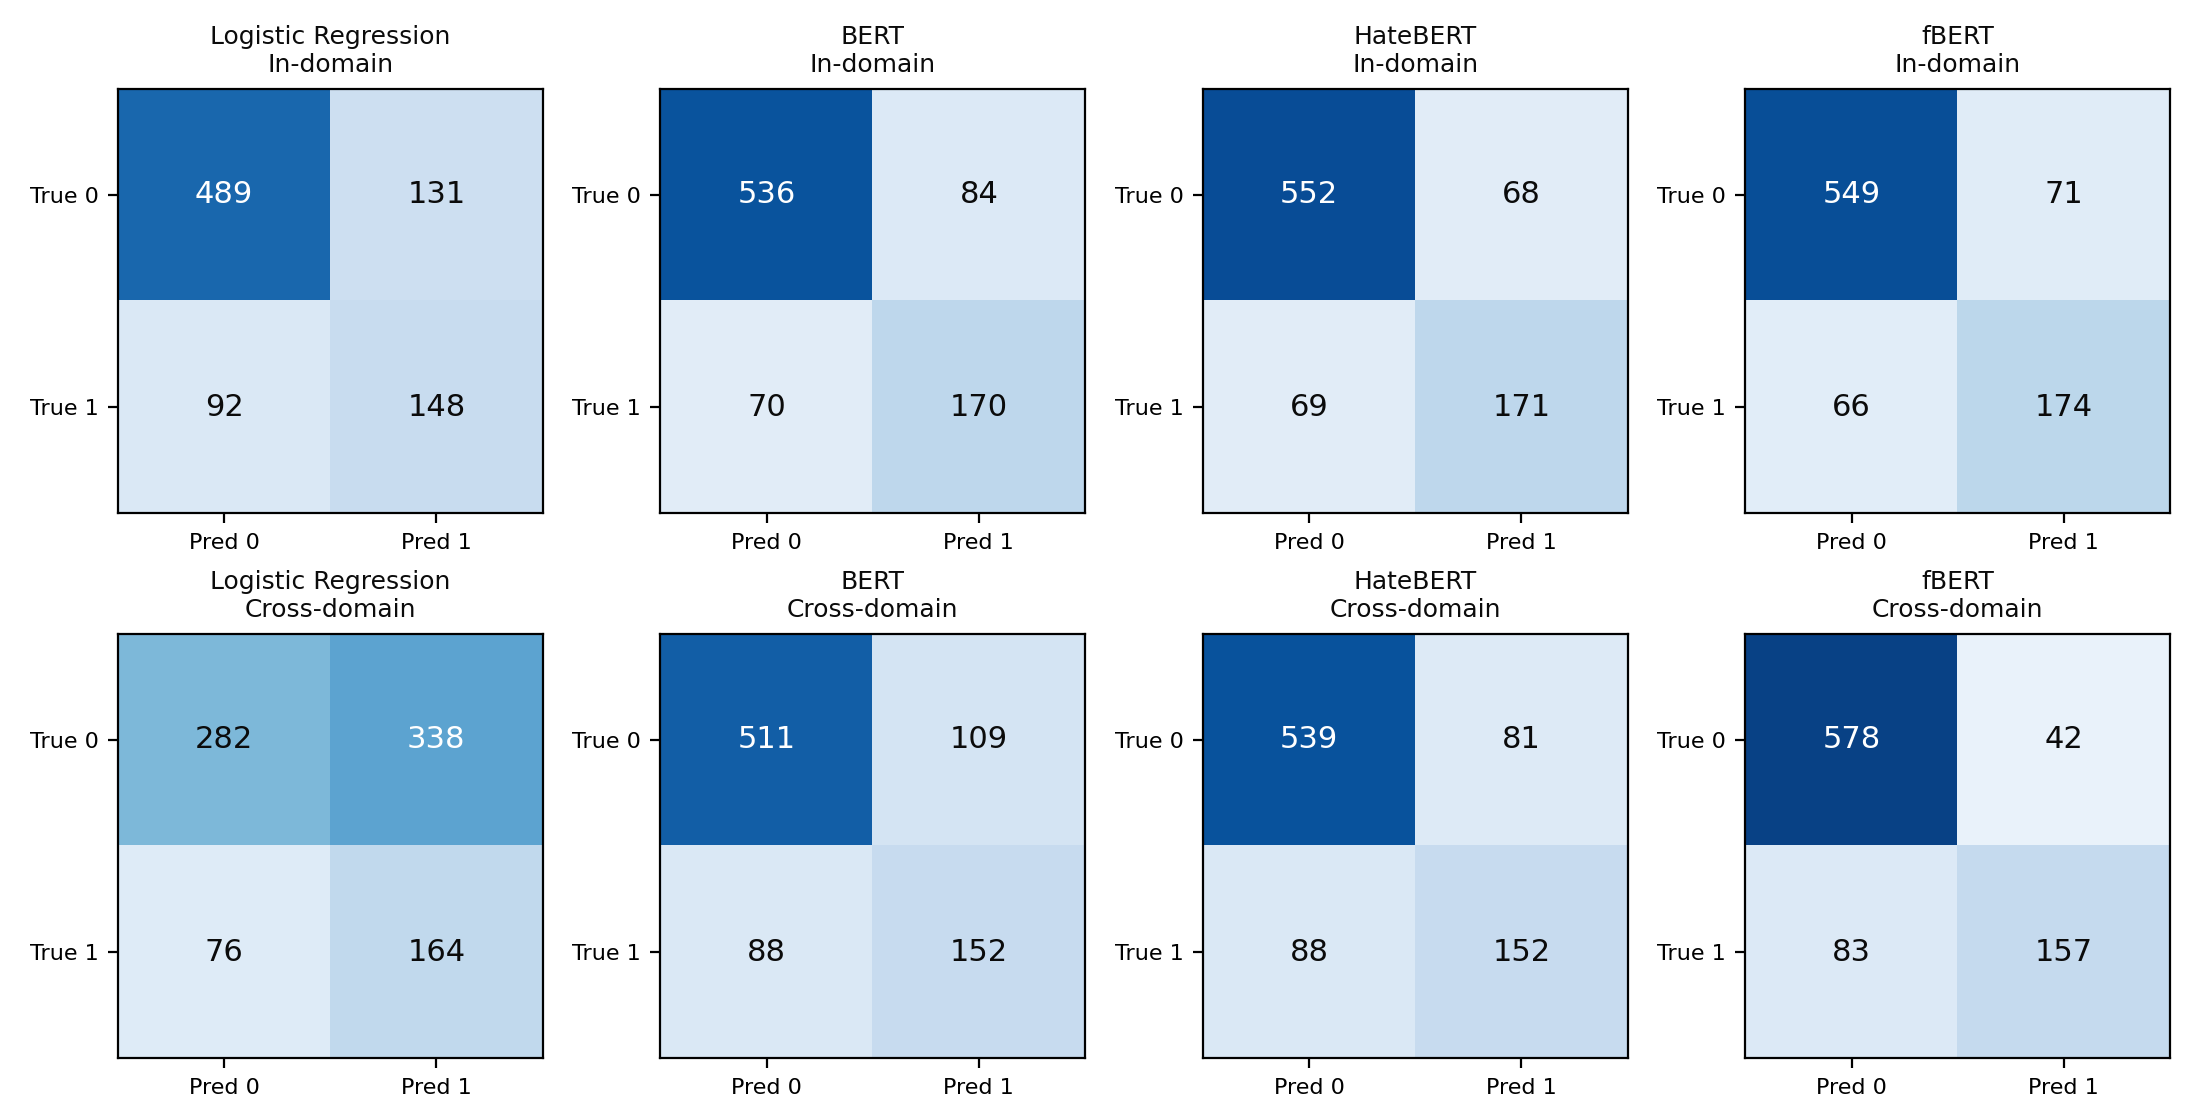

,model,setting,TN,FP,FN,TP,false_positive_rate,false_negative_rate,predicted_offensive_percent
0,Logistic Regression,In-domain,489,131,92,148,0.211,0.383,32.442
1,Logistic Regression,Cross-domain,282,338,76,164,0.545,0.317,58.372
2,BERT,In-domain,536,84,70,170,0.135,0.292,29.535
3,BERT,Cross-domain,511,109,88,152,0.176,0.367,30.349
4,HateBERT,In-domain,552,68,69,171,0.110,0.288,27.791
5,HateBERT,Cross-domain,539,81,88,152,0.131,0.367,27.093
6,fBERT,In-domain,549,71,66,174,0.115,0.275,28.488
7,fBERT,Cross-domain,578,42,83,157,0.068,0.346,23.140


In [10]:
display(Image(filename='figures/confusion_matrices_all.png', width=950))
display(pd.read_csv('tables/error_summary_all.csv').round(3))

## 5.3 Size of the cross-domain drop

The McNemar test compares the errors of the in-domain and cross-domain model on the same 860 tweets.

In [11]:
display(drops.round(4))
display(pd.read_csv('tables/paired_in_vs_cross.csv').round(4))
print('Pairwise model comparisons (exact McNemar):')
display(pd.read_csv('tables/pairwise_model_tests.csv').round(4))

,model,macro_f1_in,macro_f1_cross,abs_drop_macro_f1,rel_drop_macro_f1_percent,drop_f1_0,drop_f1_1,change_precision_1,change_recall_1
0,Logistic Regression,0.6923,0.5094,0.1830,26.4264,0.2376,0.1283,-0.2038,0.0667
1,BERT,0.7813,0.7226,0.0587,7.5173,0.0360,0.0815,-0.0869,-0.0750
2,HateBERT,0.8018,0.7536,0.0482,6.0122,0.0251,0.0713,-0.0631,-0.0792
3,fBERT,0.8033,0.8088,-0.0055,-0.6901,-0.0134,0.0023,0.0787,-0.0708


,model,both_correct,only_in_domain_correct,only_cross_domain_correct,both_wrong,mcnemar_exact_p
0,Logistic Regression,341,296,105,118,0.0000
1,BERT,599,107,64,90,0.0013
2,HateBERT,653,70,38,99,0.0027
3,fBERT,689,34,46,91,0.2185


Pairwise model comparisons (exact McNemar):


,setting,model_a,model_b,only_a_correct,only_b_correct,mcnemar_exact_p
0,In-domain,fBERT,HateBERT,40,40,1.0000
1,In-domain,fBERT,BERT,66,49,0.1354
2,In-domain,HateBERT,BERT,64,47,0.1285
3,Cross-domain,fBERT,HateBERT,79,35,0.0000
4,Cross-domain,fBERT,BERT,109,37,0.0000
5,Cross-domain,HateBERT,BERT,97,69,0.0358


## 5.4 Differences between the datasets

Simple properties of each dataset (in percent of messages) and how many of the test words appear in each training set. Swear words and insults are found with a short hand-made list (EXPLICIT in integrate_all.py).

In [12]:
display(profile.set_index('dataset').T.round(2))

dataset,OLID train small,HASOC train,OLID test
has_@USER_placeholder_%,92.67,0.00,38.49
has_real_@mention_%,0.00,51.54,0.00
has_URL_placeholder_%,14.05,0.00,55.93
has_http_link_%,0.00,0.00,0.00
has_hashtag_%,14.23,98.38,73.84
hashtags_per_message,0.40,3.23,2.27
has_explicit_word_%,13.69,34.45,12.21
explicit_word_%_offensive,31.00,45.64,36.67
explicit_word_%_non_offensive,2.78,27.40,2.74
test_token_coverage_%,89.08,81.60,NaN


The words with the highest weights for each class in the Logistic Regression model trained on HASOC. The Part 1 model is trained again here, and the code checks that it gives the same predictions as before.

In [13]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

hasoc = data['HASOC train']
lr = Pipeline([('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
               ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))])
lr.fit(hasoc.text, hasoc.labels)
assert (lr.predict(test.text) == preds[('Logistic Regression', 'Cross-domain')]).all()
vocab, w = lr[0].get_feature_names_out(), lr[1].coef_[0]
order = np.argsort(w)
display(pd.DataFrame({'strongest offensive cues': vocab[order[::-1][:20]],
                      'strongest non-offensive cues': vocab[order[:20]]}))

,strongest offensive cues,strongest non-offensive cues
0,fuck,dhonikeepstheglove
1,fucking,doctorsfightback
2,you,dhoni
3,gandinaaliabuse,doctors
4,traitor,new
5,dickhead,shameonicc
6,stupid,borisjohnsonshouldnotbepm
7,shit,happy johnmccainday
8,ass,first
9,he,indvaus


## 5.5 Errors by swear words and by message length

In [14]:
display(pd.read_csv('tables/explicit_word_analysis.csv').round(3))
length = pd.read_csv('tables/errors_by_length_all.csv')
display(length.pivot_table(index=['model', 'setting'], columns='length_group', values='error_rate', sort=False).round(3))

,model,setting,subset,n_offensive,recall_offensive,n_non_offensive,fpr_non_offensive
0,Logistic Regression,In-domain,with explicit word,88,0.909,17,0.706
1,Logistic Regression,In-domain,without explicit word,152,0.447,603,0.197
2,Logistic Regression,Cross-domain,with explicit word,88,0.807,17,1.000
3,Logistic Regression,Cross-domain,without explicit word,152,0.612,603,0.532
4,BERT,In-domain,with explicit word,88,0.966,17,0.765
5,BERT,In-domain,without explicit word,152,0.559,603,0.118
6,BERT,Cross-domain,with explicit word,88,0.841,17,0.882
7,BERT,Cross-domain,without explicit word,152,0.513,603,0.156
8,HateBERT,In-domain,with explicit word,88,0.955,17,0.765
9,HateBERT,In-domain,without explicit word,152,0.572,603,0.091


length_group                      0-15 words  16-30 words  31+ words
model               setting                                         
Logistic Regression In-domain          0.222        0.259      0.296
                    Cross-domain       0.385        0.508      0.546
BERT                In-domain          0.171        0.177      0.189
                    Cross-domain       0.185        0.233      0.268
HateBERT            In-domain          0.131        0.164      0.182
                    Cross-domain       0.196        0.184      0.211
fBERT               In-domain          0.153        0.151      0.175
                    Cross-domain       0.131        0.164      0.139

## 5.6 Tweets that all transformer models get wrong in both settings

In [15]:
hard = pd.read_csv('tables/hard_examples_all_transformers_wrong.csv')
print(len(hard), 'tweets |', (hard.labels == 1).sum(), 'offensive,', (hard.labels == 0).sum(), 'non-offensive')
display(hard.head(15))

38 tweets | 25 offensive, 13 non-offensive


,id,text,labels
0,60133,#NoPasaran: Unity demo to oppose the far-right...,1
1,83155,#HIAC Damn Matt Hardy and Randy Orton put on ...,0
2,30900,@USER @USER @USER Are you referring to how the...,0
3,54053,Are you fucking serious? URL,0
4,62945,@USER @USER @USER I got in a pretty deep debat...,0
5,91217,@USER My only point of contention is this. He...,0
6,91036,#BlaseyFord It’s so comical that liberals alwa...,1
7,22882,#Ted always has a feel for the most appropriat...,1
8,24049,#SierraBurgessIsALoser She is me when my phon...,1
9,34575,#EmmyAwards2018 - Ratings tank as expected. W...,1


## 5.7 Summary
- In-domain, fBERT (0.8033) and HateBERT (0.8018) have the best macro-F1 and are not significantly different. BERT gets 0.7813 and Logistic Regression 0.6923.
- Cross-domain, fBERT is best with 0.8088, significantly better than HateBERT (0.7536) and BERT (0.7226). Logistic Regression drops to 0.5094.
- The drop is 18.3 points for Logistic Regression (26.4%), 5.9 for BERT (7.5%), 4.8 for HateBERT (6.0%) and zero for fBERT.
- Main reasons for the drop: HASOC labels swearing differently (27% of its non-offensive posts contain a swear word, against 3% in OLID), the topics are different, and the formatting is different (@USER and URL placeholders against real user names and hashtags). Message length matters less. fBERT does not drop because it was pre-trained on OLID-style data.

The full discussion is in the report.